# 02: Preprocessing checks (Stage 2)

This notebook **checks** the model-ready tables built in Stage 2. It does not build them: the reusable code is in `src/`, and one command per horizon rebuilds everything from the raw data:

```
python -m src.pipeline --horizon 15min
python -m src.pipeline --horizon 1h
python -m src.pipeline --horizon dayahead
```

Every decision shown here is also recorded, with its numbers, in the `PLAN.md` Change log.

## 1. Setup

In [1]:
import sys
sys.path.insert(0, '..')

import subprocess
import pandas as pd
import matplotlib.pyplot as plt

from src import splits

## 2. How a station is cleaned (order of the rules)

`src/pipeline.py::clean_station` applies the rules from `src/preprocess.py` in this order:

| Step | Rule | Why (evidence) |
|---|---|---|
| 1 | Duplicate timestamps: identical copies merged, disagreeing copies set to missing | 4 files repeat timestamps; we cannot know which copy is right |
| 2 | Power outside [0, 1.2 x rated] set to missing (not clipped) | glitches down to -8.7 MW and up to 31.8 MW; clipping would invent a value |
| 3 | Hourly stations shifted 1 h back to the interval-start label | Stage 1: hourly files are labelled at the interval end |
| 4 | Rows after 2023-12-31 dropped | `Zone L1 (Station 1)` runs into 2024 |
| 5 | `Zone A2` used from 2023-05-31 only | capacity change: about 0.25 x rated before, 0.75 x after |
| 6 | Regular grid; gaps up to 1 h forward-filled, `is_filled` kept | most gaps are whole lost days, which are not filled |
| 7 | Power set to 0 when the sun is below 5 degrees | removes rare night glitches; costs at most 0.53 % of energy |
| 8 | Power divided by the `.ttl` rated power | makes stations comparable; uses metadata only, so no leakage |

Weather: 1-min values averaged to 15 min / 1 h (at least 80 % of minutes needed), irradiance above 2000 W/m2 and wind above 20 m/s set to missing. Humidity and rainfall are **not used** (faulty sensor periods; no 2021 rainfall).

## 3. Rows per horizon, role and split

`role`: **seen** stations are used for training; **unseen** stations are never trained on (test only). `usable_rows` are targets that are observed, not gap-filled and not a zero-output fault: only these are used for training and evaluation.

In [2]:
summary = pd.read_csv('../results/tables/02_split_summary.csv')
summary

,horizon,role,split,rows,usable_rows,stations,first,last
0,1h,seen,test,376484,368003,43,2023-01-01 00:00:00,2023-12-31 23:00:00
1,1h,seen,train,457207,447570,43,2021-03-09 23:00:00,2022-09-30 23:00:00
2,1h,seen,val,94944,92997,43,2022-10-01 00:00:00,2022-12-31 23:00:00
3,1h,unseen,test,116587,114357,14,2023-01-01 00:00:00,2023-12-31 23:00:00
4,1h,unseen,train,67440,66833,9,2021-06-01 00:00:00,2022-09-30 23:00:00
5,1h,unseen,val,20490,20278,11,2022-10-01 00:00:00,2022-12-31 23:00:00
6,15min,seen,test,840960,837169,24,2023-01-01 00:00:00,2023-12-31 23:45:00
7,15min,seen,train,934464,930333,24,2021-06-01 00:00:00,2022-09-30 23:45:00
8,15min,seen,val,211968,211278,24,2022-10-01 00:00:00,2022-12-31 23:45:00
9,15min,unseen,test,361344,356185,11,2023-01-01 00:00:00,2023-12-31 23:45:00


## 4. Station sets

Built by `src/splits.py::station_sets` from the Stage 1 gate plus three later decisions: `UG Hall4 Flexible PV` dropped, `Zone A2` test-only, and 6 random hold-outs (seed 42) drawn once from the seen optimizer stations, so they are unseen at every horizon.

In [3]:
sets = splits.station_sets()
sets.groupby(['has_optimizer', 'role']).size()

has_optimizer  role    
False          excluded     1
               seen        19
               unseen       3
True           excluded     2
               seen        24
               unseen      11
dtype: int64

In [4]:
for horizon in ['15min', '1h', 'dayahead']:
    counts = {role: len(splits.stations_for(horizon, role)) for role in ['seen', 'unseen', 'excluded']}
    print(horizon, counts)

15min {'seen': 24, 'unseen': 11, 'excluded': 2}
1h {'seen': 43, 'unseen': 14, 'excluded': 3}
dayahead {'seen': 43, 'unseen': 14, 'excluded': 3}


In [5]:
not_seen = sets[sets['role'] != 'seen']
not_seen[['station', 'has_optimizer', 'role', 'reason']].sort_values('role')

,station,has_optimizer,role,reason
9,SQ Block P,True,excluded,no training data and under 180 test days (Stag...
17,Shaw Auditorium,True,excluded,no training data and under 180 test days (Stag...
56,UG Hall4 Flexible PV,False,excluded,zero output in 64 % of high-irradiance hours
2,LSK South,True,unseen,"random hold-out (seed 42); has training data, ..."
3,Library,True,unseen,little or no training data (Stage 1 gate)
14,SQ3,True,unseen,"random hold-out (seed 42); has training data, ..."
20,UG Hall3,True,unseen,"random hold-out (seed 42); has training data, ..."
23,UG Hall7,True,unseen,"random hold-out (seed 42); has training data, ..."
24,UG Hall8,True,unseen,little or no training data (Stage 1 gate)
25,UG Hall9,True,unseen,little or no training data (Stage 1 gate)


## 5. Zero-output faults

Hours with power = 0 W while irradiance is at least 400 W/m2. `UG Hall4 Flexible PV` (64 % of its high-irradiance hours) is dropped; for every other station these rows are flagged (`target_is_fault`) and left out of training and evaluation, but kept for Stage 8 (fault flagging).

In [6]:
zero = pd.read_csv('../results/tables/02_zero_output.csv')
zero[['station', 'has_optimizer', 'high_irr_hours', 'zero_hours', 'zero_pct', 'zero_days']].head(8)

,station,has_optimizer,high_irr_hours,zero_hours,zero_pct,zero_days
0,UG Hall4 Flexible PV,False,2268,1452,64.02,310
1,SQ567 Flexible PV,False,3186,286,8.98,74
2,SQ18,False,2384,88,3.69,16
3,Tower A,False,2646,61,2.31,11
4,Zone L1 (Station 1),False,2061,40,1.94,14
5,Zone L1(Station 2),False,3112,32,1.03,12
6,CYT (Station 1),False,3436,30,0.87,8
7,SQ1,True,3699,27,0.73,7


## 6. Load the 1-h table

One row per station and target hour. The 15-min and day-ahead tables have the same layout (different features).

In [7]:
t1h = pd.read_parquet('../data/processed/features_1h.parquet')
t1h.shape

(1133152, 36)

In [8]:
list(t1h.columns)

['hour',
 'day_of_year',
 'month',
 'hour_sin',
 'hour_cos',
 'doy_sin',
 'doy_cos',
 'sun_elevation',
 'sun_azimuth',
 'clearsky_ghi',
 'power_lag1',
 'power_lag2',
 'power_lag3',
 'power_lag24',
 'power_mean3',
 'power_std3',
 'irr_lag1',
 'irr_lag2',
 'irr_mean3',
 'csi_lag1',
 'csi_lag2',
 'csi_mean3',
 'temperature_lag1',
 'wind_speed_lag1',
 'pressure_lag1',
 'visibility_lag1',
 'target',
 'target_is_filled',
 'target_is_fault',
 'usable',
 'station',
 'is_optimizer',
 'tilt_deg',
 'multi_orientation',
 'role',
 'split']

## 7. One station: a clean day and a gap-filled day

`Zone L1(Station 2)` (hourly station) has the most filled hours. Filled values (red) may be used as **features** (lags), but a filled **target** is never used for evaluation.

In [9]:
station = t1h[t1h['station'] == 'Zone L1(Station 2)']
filled_per_day = station.groupby(station.index.normalize())['target_is_filled'].sum()
filled_day = filled_per_day.idxmax()
filled_day

Timestamp('2022-04-22 00:00:00')

In [10]:
# a clean day: every hour of the day is usable (observed, not filled, not a fault)
all_usable = station.groupby(station.index.normalize())['usable'].all()
clean_days = all_usable[all_usable].index
clean_day = clean_days[clean_days.month == 7][0]
clean_day

Timestamp('2021-07-01 00:00:00')

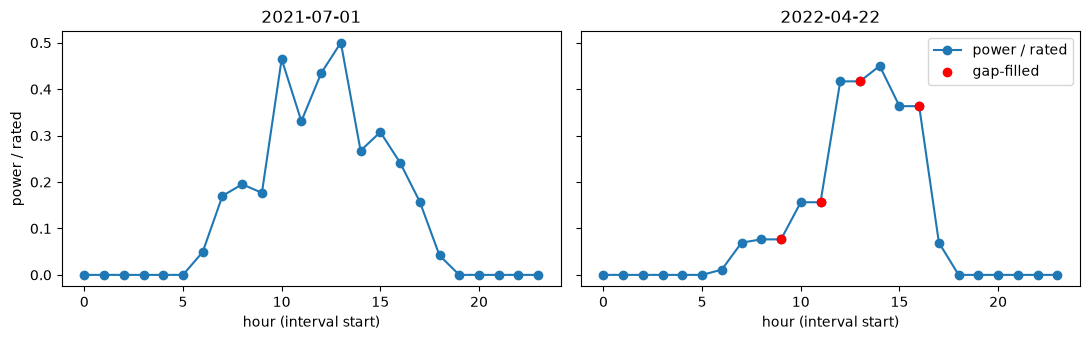

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5), sharey=True)

for ax, day in zip(axes, [clean_day, filled_day]):
    d = station.loc[str(day.date())]
    ax.plot(d.index.hour, d['target'], marker='o', label='power / rated')
    filled = d[d['target_is_filled']]
    ax.scatter(filled.index.hour, filled['target'], color='red', zorder=3, label='gap-filled')
    ax.set_title(str(day.date()))
    ax.set_xlabel('hour (interval start)')

axes[0].set_ylabel('power / rated')
axes[1].legend()
plt.tight_layout()
plt.savefig('../results/figures/02_clean_vs_filled_day.png', dpi=120)
plt.show()

## 8. Missing features (daytime, usable, seen rows)

`tilt_deg` is missing on purpose for the 11 `Mixed` stations (tree models handle this; for the linear model and LSTM it will be filled from train stations only). Other features are rarely missing.

In [12]:
not_features = ['target', 'target_is_filled', 'target_is_fault', 'usable', 'station', 'role', 'split']
feature_cols = [c for c in t1h.columns if c not in not_features]

day = t1h[t1h['usable'] & (t1h['sun_elevation'] >= 5) & (t1h['role'] == 'seen')]
missing = day[feature_cols].isna().mean() * 100
missing.sort_values(ascending=False).head(8).round(2)

tilt_deg            24.42
power_lag24          1.39
irr_mean3            0.67
wind_speed_lag1      0.65
irr_lag2             0.62
temperature_lag1     0.62
irr_lag1             0.61
visibility_lag1      0.61
dtype: float64

## 9. Seasons in training

Every season must be in the training data. Validation (Q4 2022) has only autumn and winter, so tuning never sees spring or summer weather; this is a limitation for the report.

In [13]:
day = day.copy()
day['season'] = splits.season(day.index)
season_rows = day.groupby(['split', 'season']).size().unstack()
season_rows

season,autumn,spring,summer,winter
split,,,,
test,38822.0,44382.0,48383.0,37213.0
train,43243.0,52846.0,77144.0,36408.0
val,25894.0,NaN,NaN,12620.0


## 10. Leakage tests

`tests/test_leakage.py` (13 tests on made-up data). The main test replaces every measured value from the forecast issue time onward with junk and checks that no feature changes; two control tests show that a cut one step too early is caught.

In [14]:
result = subprocess.run([sys.executable, '-m', 'pytest', '-q', '--color=no'], cwd='..', capture_output=True, text=True)
print(result.stdout[-400:])

.............                                                            [100%]
13 passed in 6.61s



## 11. Summary

- Three model-ready tables (15 min, 1 h, day-ahead), rebuilt by one command each; 98-99 % of targets are usable.
- Stations: 15 min 24 seen / 11 unseen; 1 h and day-ahead 43 seen / 14 unseen.
- Chronological split: train to 2022-09-30, validation Q4 2022, test 2023; all four seasons in training.
- No feature uses information from the forecast issue time or later (leakage tests pass).
- Limits: validation covers autumn and winter only; the irradiance sensor is assumed horizontal (unverified); the interval-label convention is inferred from correlation (Stage 1).